In [18]:
import pandas as pd
df=pd.read_csv("01_linear_delivery_time.csv")
df

,Distance_km,Delivery_Time_min
0,11.86,48.8
1,28.57,96.0
2,22.23,83.8
3,18.36,80.9
4,5.52,36.6
...,...,...
245,27.92,109.6
246,13.42,70.1
247,29.03,108.5
248,28.94,119.1


In [2]:
x=df[['Distance_km']]
y=df['Delivery_Time_min']

In [3]:
from sklearn.model_selection import train_test_split

X_train ,X_test, Y_train, Y_test = train_test_split(x,y,train_size=0.8)

X_train.head()

,Distance_km
112,27.96
238,19.72
62,25.03
64,9.15
51,23.48


In [4]:
X_test.head()

,Distance_km
126,24.72
63,11.35
219,25.63
146,18.68
153,15.19


In [5]:
from sklearn import linear_model

model = linear_model.LinearRegression()
model.fit(X_train,Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [6]:
from sklearn.metrics import r2_score
y_pred = model.predict(X_test)
score = r2_score(Y_test, y_pred) 
print(f"Accuracy (R² Score): {score * 100:.2f}%")

Accuracy (R² Score): 94.48%


In [14]:
a = float(input("Enter the Km coverd: "))
predicted_value = model.predict([[a]])
print("Time Taken to cover the",a,"Km", predicted_value)


Time Taken to cover the 34.0 Km [122.16329984]


c:\Users\<user>\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


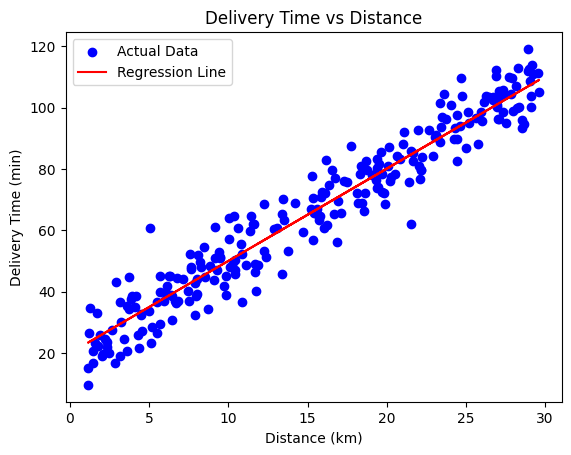

In [8]:
import matplotlib.pyplot as plt

# 1. Create scatter plot of actual data points
plt.scatter(x, y, color='blue',label='Actual Data')

# 2. Plot the fitted regression line using model predictions
plt.plot(x, model.predict(x), color='red',label='Regression Line')

# 3. Add labels and title
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Time (min)')
plt.title('Delivery Time vs Distance')
plt.legend()

plt.show()

In [15]:
import joblib

joblib.dump(model, "delivery_model.pkl")

['delivery_model.pkl']

In [16]:
import joblib

loaded_model = joblib.load("delivery_model.pkl")

print("Model Loaded Successfully", loaded_model)

Model Loaded Successfully LinearRegression()


In [17]:
import pandas as pd

distance = float(input("Enter the Km covered: "))

input_data = pd.DataFrame({
    "Distance_km": [distance]
})

prediction = loaded_model.predict(input_data)

print("Time Taken to cover", distance, "Km:", prediction[0], "minutes")

Time Taken to cover 34.0 Km: 122.16329983675118 minutes
